Universidad de Buenos Aires

FIUBA - CEIA

Vision por computadora 1

Azar Miguel Augusto

a2702

---

# Trabajo práctico 1

Resolucion de los dos ejercicios propuestos.

Los archivos provistos son:
- Ejercicio 1: a la carpeta `white_patch` (`/content/white_patch/`). Archivos: `wp_red2.jpg`, `wp_green2.jpg`, `wp_blue.jpg`, `wp_red.png`, `wp_green.png`, `test_red.png`, `test_green.png`, `test_blue.png`.
- Ejercicio 2: a la raíz de Colab (`/content/`). Archivos: `img1_tp.png` e `img2_tp.png`.

In [1]:
import glob
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

# Parte 1: algoritmo White Patch

---

**Consigna**
1. Implementar el algoritmo *White Patch* para librarnos de las diferencias de color de iluminación.
2. Mostrar los resultados obtenidos y analizar las posibles fallas (si es que las hay) en el caso de White Patch.

---

**Comentario sobre la forma de resolverlo.**

Dadas las imagenes que tienen diferentes iluminaciones teoricamente tienen algo blanco que refleja toda la luz de la fuente. El valor más alto de cada canal (R, G, B) indica qué color tiene esa luz. Para quitar ese color el algoritmo divide cada canal por su máximo y reescala el resultado a 0–255:

$$I'_c(x,y) = 255 \cdot \frac{I_c(x,y)}{\max_{x,y} I_c(x,y)} \qquad c \in \{R,G,B\}$$

donde:

I: es la imagen

c: es el canal (ya sea R, G o B)

(x,y): es la posicion de un pixel para un canal determinado

## 1. Carga de imágenes

In [2]:
CARPETA = '/content/white_patch'

archivos = ['wp_red2.jpg', 'wp_green2.jpg', 'wp_blue.jpg',      # Predator
            'wp_red.png', 'wp_green.png',                       # Predator
            'test_red.png', 'test_green.png', 'test_blue.png']  # Manos

imgs, faltan = {}, []
for nombre in archivos:
    ruta = os.path.join(CARPETA, nombre)
    if not os.path.exists(ruta):
        faltan.append(nombre)
        continue
    imgs[nombre] = np.array(Image.open(ruta).convert('RGB'))   # imagen RGB como arreglo de numpy
    print(f'{nombre:15s} {imgs[nombre].shape}')

if faltan:
    print('\nNo se encontraron en', CARPETA, ':', faltan)

wp_red2.jpg     (1600, 1200, 3)
wp_green2.jpg   (1600, 1200, 3)
wp_blue.jpg     (1600, 1200, 3)
wp_red.png      (813, 481, 3)
wp_green.png    (571, 363, 3)
test_red.png    (99, 276, 3)
test_green.png  (100, 278, 3)
test_blue.png   (100, 278, 3)


## 2. Implementación de White Patch
Para cada canal se busca el valor máximo y se multiplica todo el canal por `255 / máximo`.

In [3]:
def white_patch(img):
    f = img.astype(np.float64)
    maximos = f.reshape(-1, 3).max(axis=0)          # máximo de R, G y B
    maximos = np.maximum(maximos, 1e-6)             # evita dividir por cero
    salida = f * (255.0 / maximos)                  # escala cada canal
    return np.clip(salida, 0, 255).astype(np.uint8), maximos

corregidas, maximos = {}, {}
for nombre, im in imgs.items():
    corregidas[nombre], maximos[nombre] = white_patch(im)
    print(f'{nombre:15s} máximos (R,G,B) = {maximos[nombre]}')

wp_red2.jpg     máximos (R,G,B) = [255. 201. 203.]
wp_green2.jpg   máximos (R,G,B) = [170. 255. 172.]
wp_blue.jpg     máximos (R,G,B) = [255. 255. 255.]
wp_red.png      máximos (R,G,B) = [255. 134. 122.]
wp_green.png    máximos (R,G,B) = [126. 252. 155.]
test_red.png    máximos (R,G,B) = [247. 157. 175.]
test_green.png  máximos (R,G,B) = [210. 250. 171.]
test_blue.png   máximos (R,G,B) = [165. 138. 200.]


## 3. Resultados: imágenes antes y después

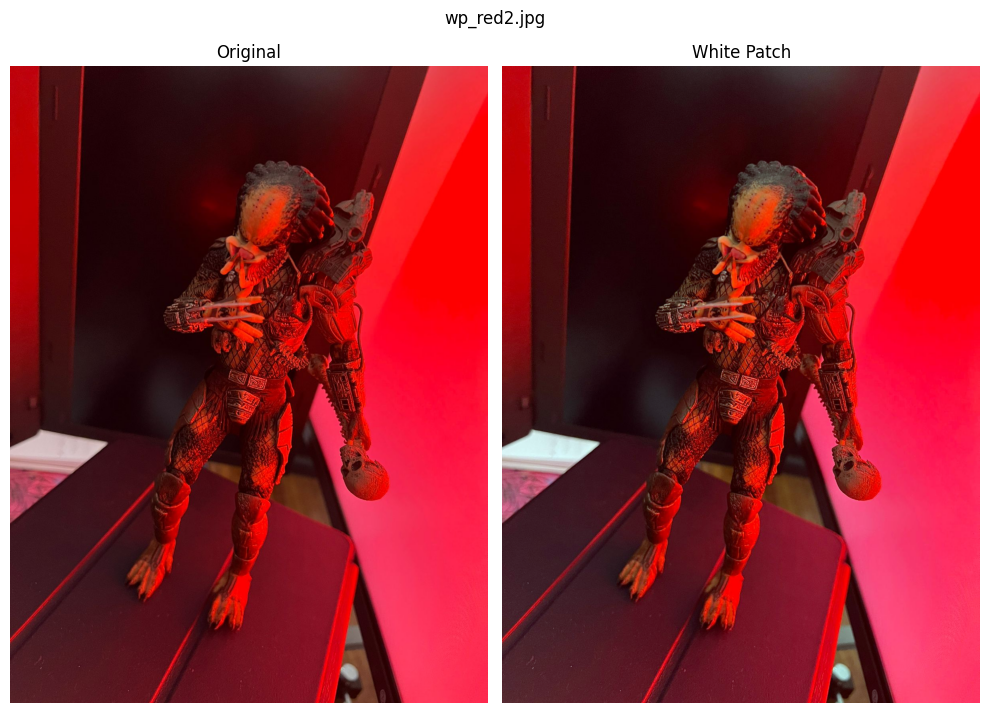

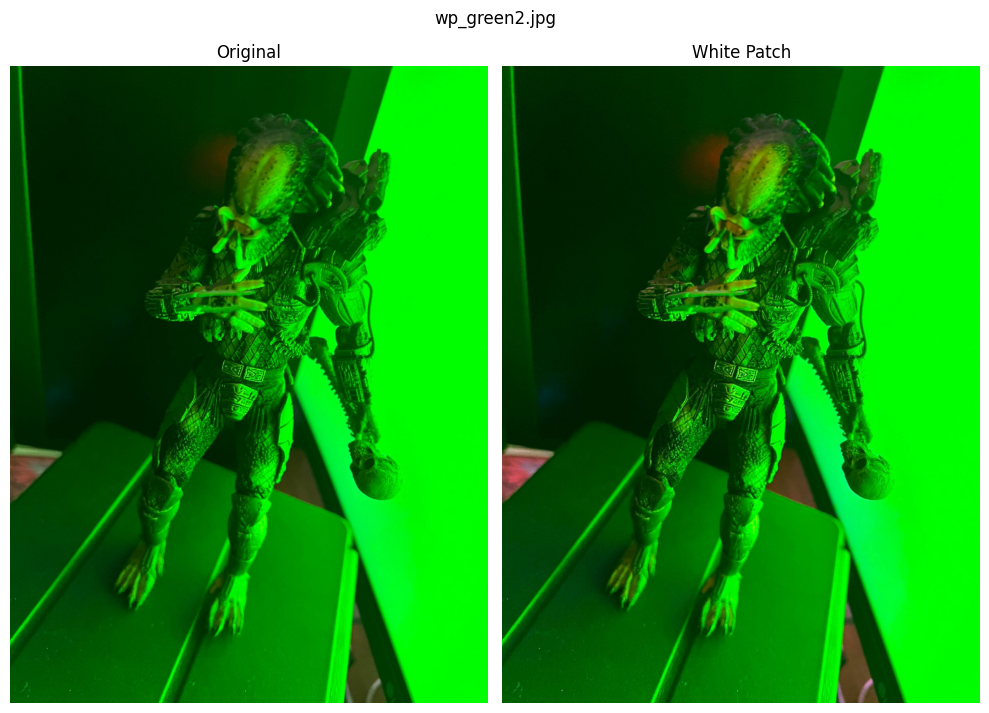

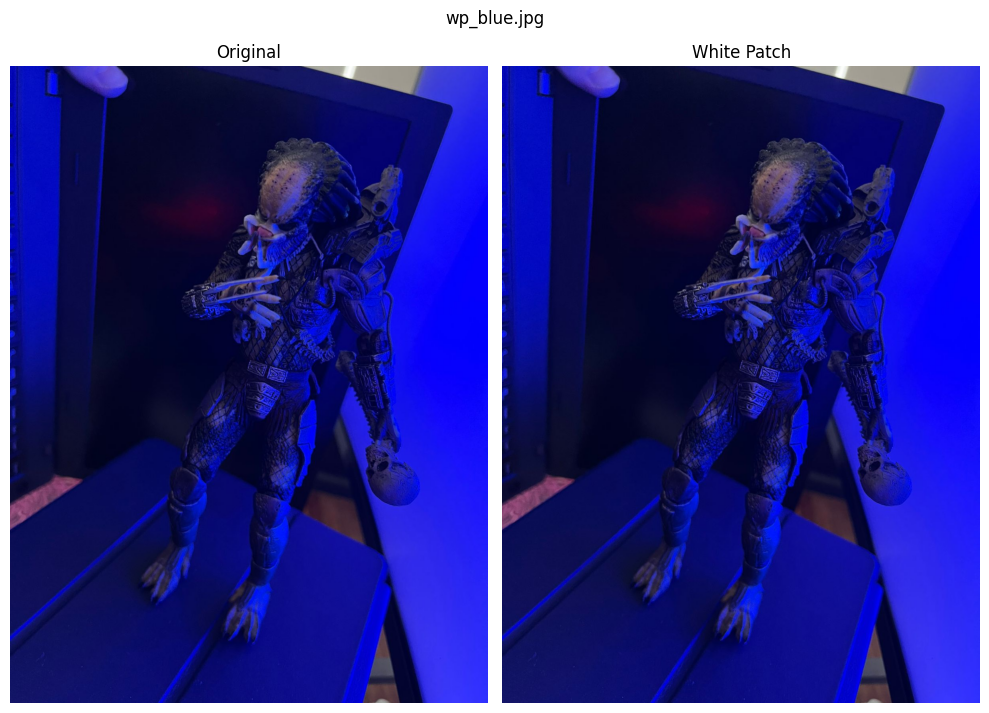

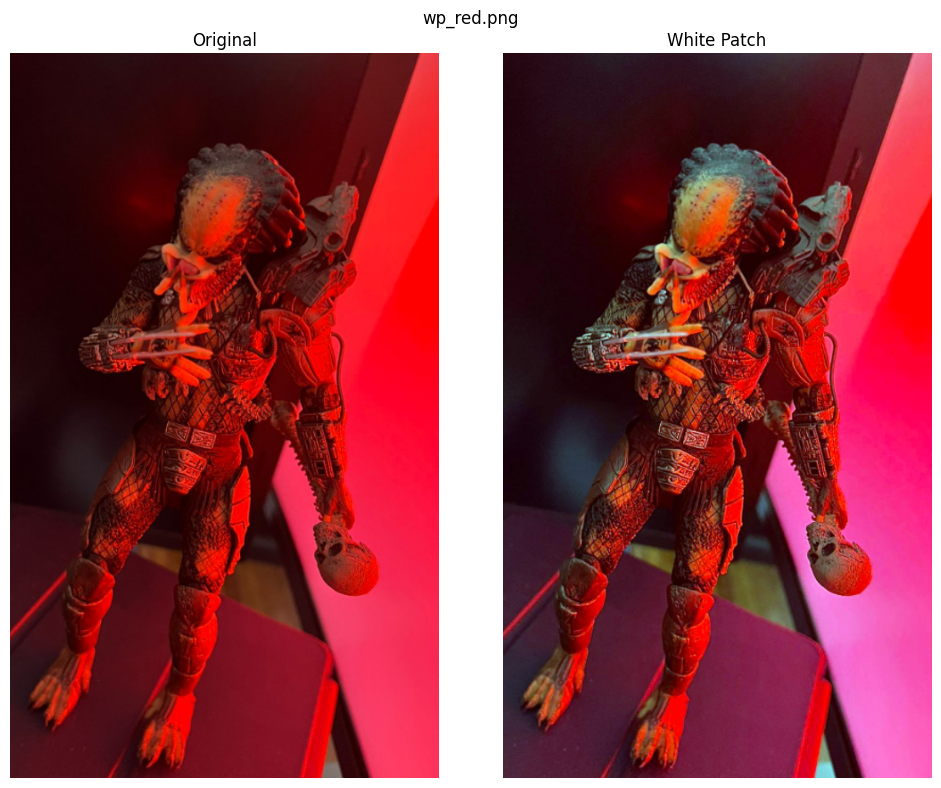

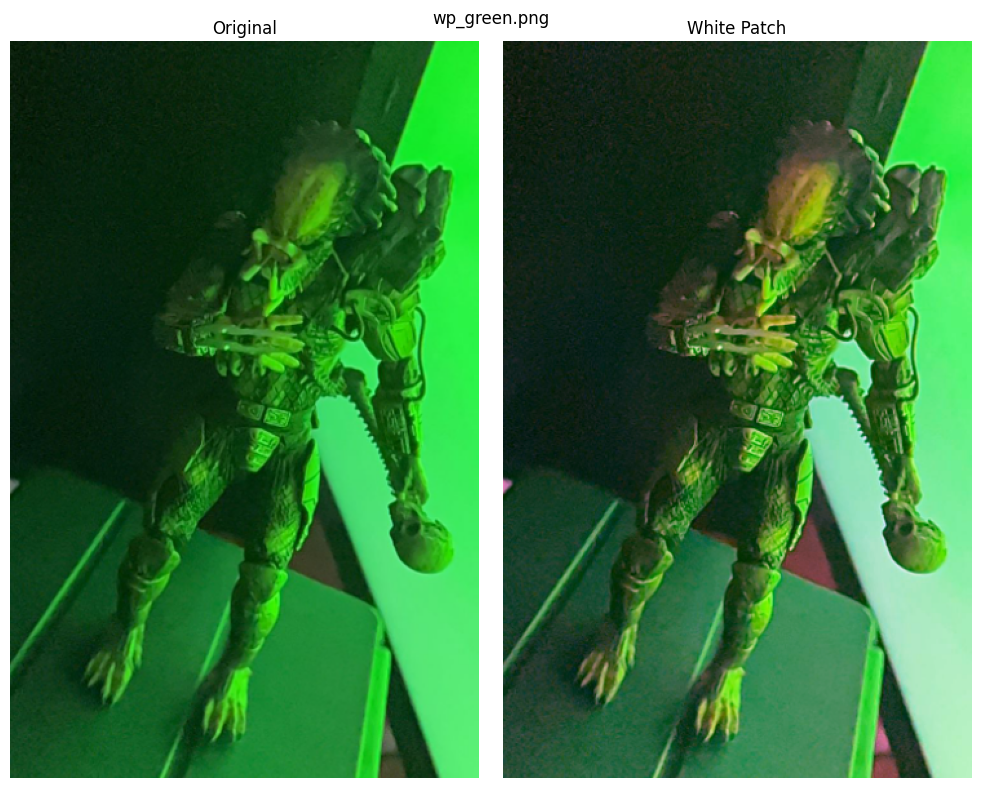

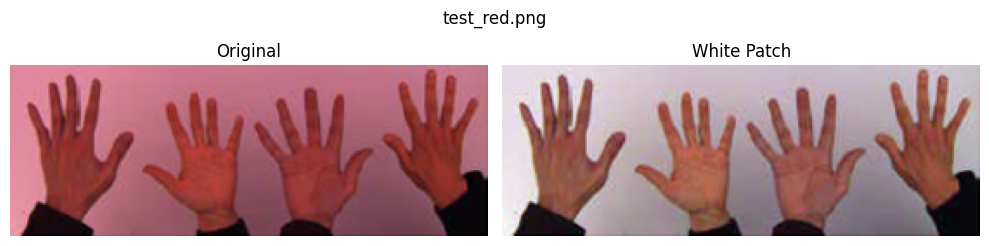

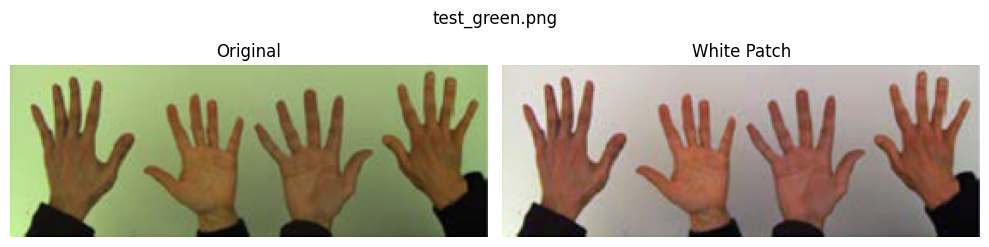

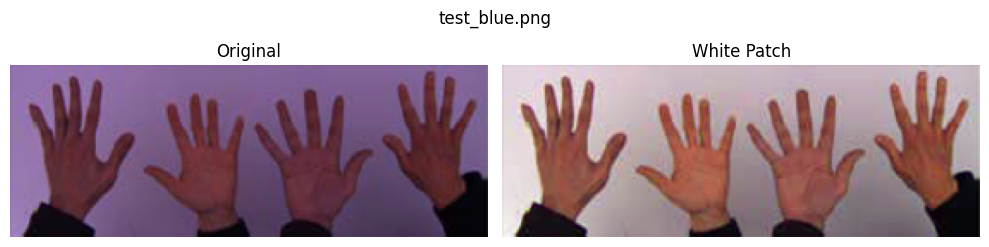

In [4]:
for nombre, im in imgs.items():
    h, w = im.shape[:2]
    fig, ax = plt.subplots(1, 2, figsize=(10, min(5 * h / w + 0.8, 8)))
    ax[0].imshow(im);                  ax[0].set_title('Original')
    ax[1].imshow(corregidas[nombre]);  ax[1].set_title('White Patch')
    for a in ax:
        a.axis('off')
        print("") # separo las imagenes
    fig.suptitle(nombre)
    plt.tight_layout()
    plt.show()

## 4. Análisis de posibles fallas

### 4.1 El algoritmo falla, en la tabla siguiente analizo el motivo

El algoritmo White Patch toma el valor más alto de cada canal y escala ese canal para que el máximo pase a ser 255. La tabla muestra, para cada imagen:
- **max R / G / B:** el valor más alto de cada canal (de 0 a 255).
- **factor R / G / B:** por cuánto se multiplica cada canal (255 dividido por el máximo). Un factor de 1,00 significa que ese canal no se modifica.
- **píxeles en el máx. R / G / B:** cuántos píxeles valen exactamente ese máximo. Explica dos motivos de falla:
  - **Muchos píxeles:** si el máximo es 255 y hay muchos píxeles con ese valor, la cámara llegó a su límite (el canal está saturado). Aunque la luz fuera más fuerte, quedó anotado 255, y el método lo toma como si fuera la luz real.
  - **Muy pocos píxeles (por ejemplo 1):** un punto aislado decide toda la corrección y puede no representar la luz de la escena.

**Ejemplo (`wp_red2.jpg`).** El rojo tiene 174 795 píxeles en 255 (saturado), y el verde y el azul llegan solo a 201 y 203, marcados por 1 y 6 píxeles. Los factores son 1,00 / 1,27 / 1,26: para quitar una luz roja intensa habría que subir mucho más el verde y el azul, y por eso la imagen sigue roja.

In [5]:
filas = []
for nombre, im in imgs.items():
    mx = maximos[nombre]
    fac = 255.0 / mx
    n_max = [int((im[..., k] == int(mx[k])).sum()) for k in range(3)]   # píxeles que valen exactamente el máximo
    filas.append({'imagen': nombre,
                  'max R': int(mx[0]), 'max G': int(mx[1]), 'max B': int(mx[2]),
                  'factor R': round(fac[0], 2), 'factor G': round(fac[1], 2), 'factor B': round(fac[2], 2),
                  'píxeles en el máx. R': n_max[0], 'píxeles en el máx. G': n_max[1], 'píxeles en el máx. B': n_max[2]})

tabla = pd.DataFrame(filas).set_index('imagen')
display(tabla)

,max R,max G,max B,factor R,factor G,factor B,píxeles en el máx. R,píxeles en el máx. G,píxeles en el máx. B
imagen,,,,,,,,,
wp_red2.jpg,255,201,203,1.00,1.27,1.26,174795,1,6
wp_green2.jpg,170,255,172,1.50,1.00,1.48,1,98685,1
wp_blue.jpg,255,255,255,1.00,1.00,1.00,22,54,9738
wp_red.png,255,134,122,1.00,1.90,2.09,25263,1,2
wp_green.png,126,252,155,2.02,1.01,1.65,1,1,1
test_red.png,247,157,175,1.03,1.62,1.46,1,2,1
test_green.png,210,250,171,1.21,1.02,1.49,1,3,1
test_blue.png,165,138,200,1.55,1.85,1.27,1,1,2


### 4.2 Histogramas por canal
Muestran cuántos píxeles hay de cada intensidad en R (rojo), G (verde) y B (azul), antes y después de corregir. Se usa escala logarítmica en el eje vertical para poder ver también las zonas con pocos píxeles. Si el método funciona, los tres canales deberían quedar superpuestos y repartidos de forma parecida; si un canal está saturado, se ve una barra pegada a 255.

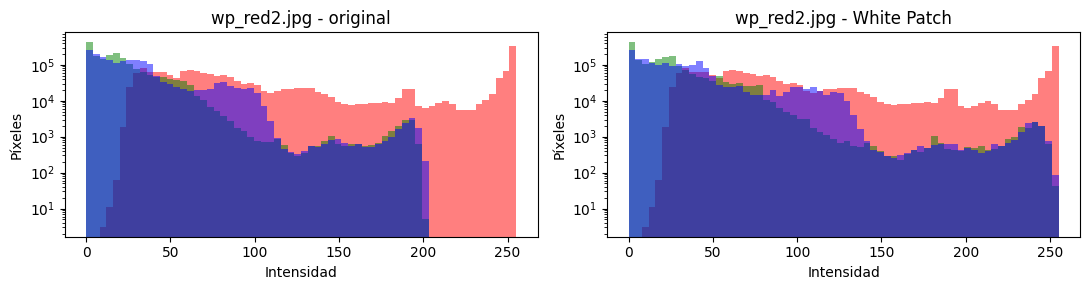

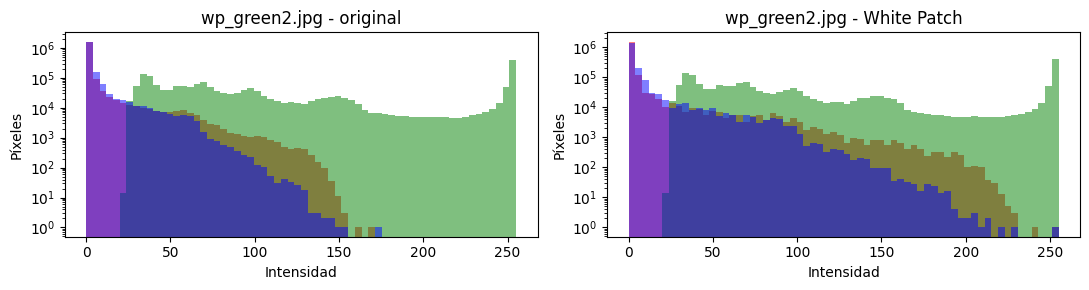

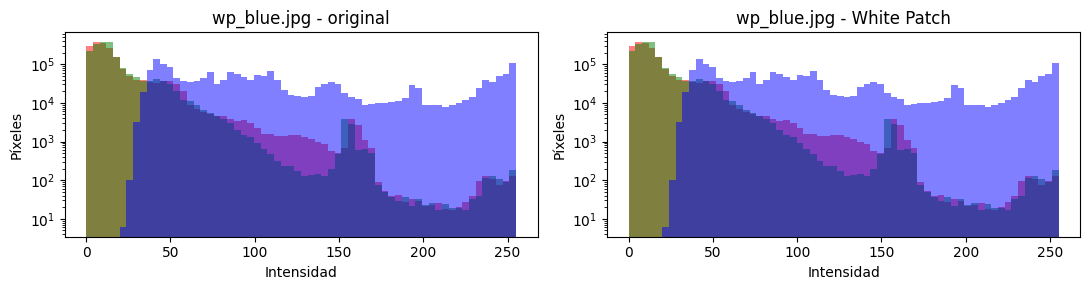

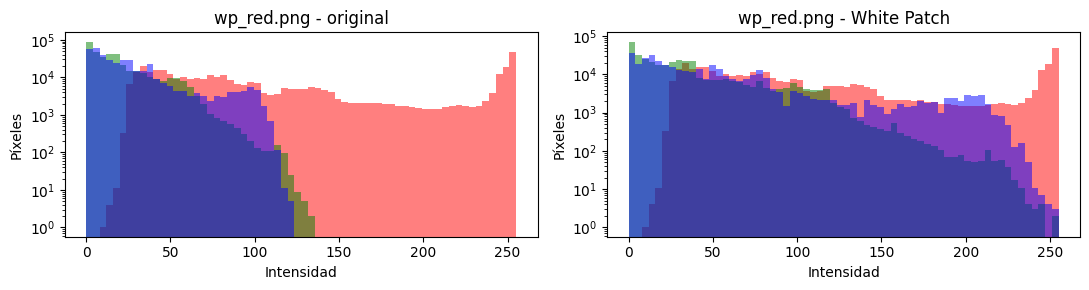

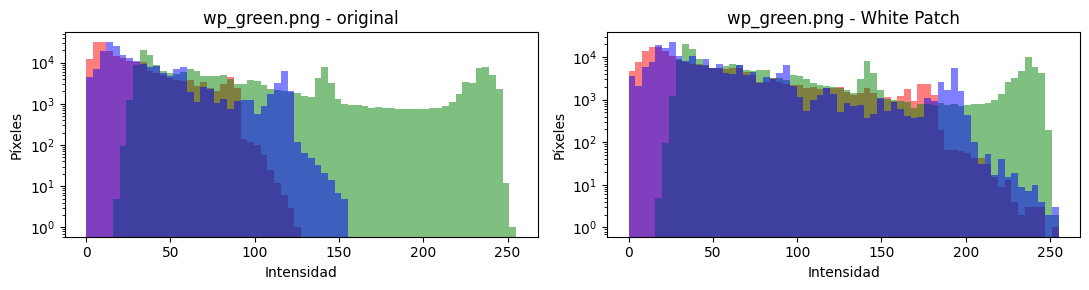

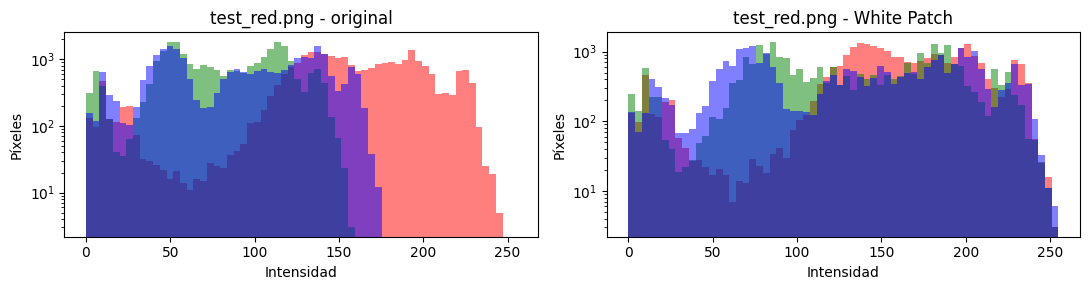

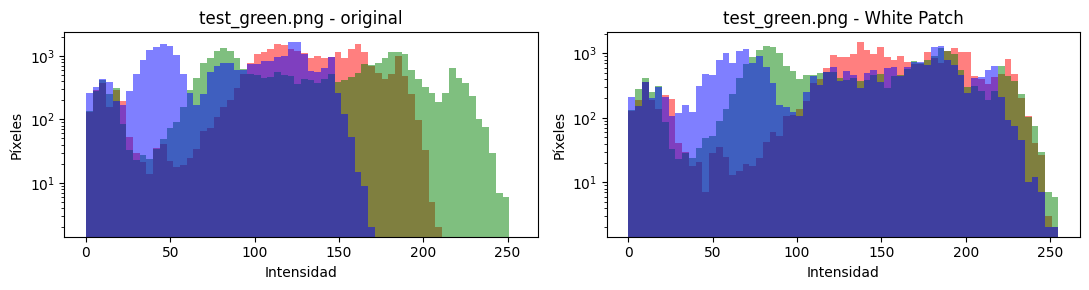

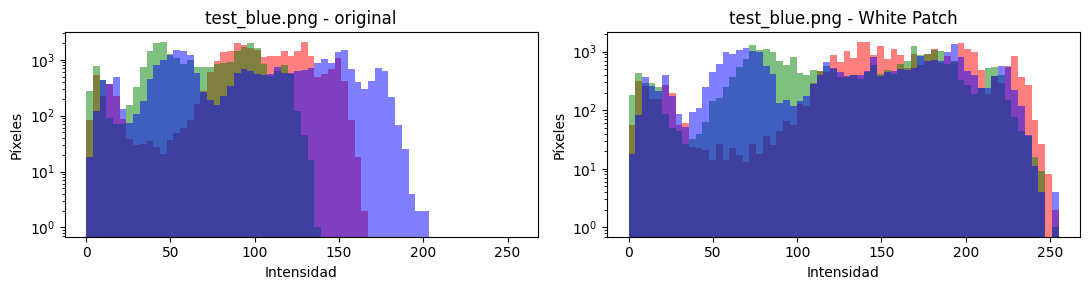

In [6]:
colores = ['r', 'g', 'b']
for nombre, im in imgs.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 3))
    for c in range(3):
        ax[0].hist(im[..., c].ravel(),                bins=64, range=(0, 255), color=colores[c], alpha=0.5)
        ax[1].hist(corregidas[nombre][..., c].ravel(), bins=64, range=(0, 255), color=colores[c], alpha=0.5)
    ax[0].set_title(f'{nombre} - original')
    ax[1].set_title(f'{nombre} - White Patch')
    for a in ax:
        a.set_yscale('log'); a.set_xlabel('Intensidad'); a.set_ylabel('Píxeles')
    plt.tight_layout()
    plt.show()

## 5. Resultado


### El algoritmo White Patch no funcionó bien
- Las imágenes siguen con un tinte fuerte del color de la luz. En `wp_red2.jpg`, `wp_green2.jpg` y `wp_blue.jpg` el cambio es leve o nulo (en `wp_green2.jpg` aparece un tono cian en la parte baja de la pared). En `wp_red.png` y `wp_green.png` la corrección es mayor pero parcial dado que la pared brillante queda rosa o verde claro en vez de blanca.
- En `wp_red2.jpg`, `wp_red.png` y `wp_green2.jpg` el canal de la luz tiene 255 como máximo y muchísimos píxeles con ese valor (174 795, 25 263 y 98 685, esto es, entre el 5 % y el 9 % de la imagen). El máximo medido queda por debajo de la luz real y los otros dos canales no se suben lo suficiente, es decir, en `wp_red2.jpg` los factores son 1,00 / 1,27 / 1,26 y la imagen sigue roja. En los histogramas, el canal de la luz queda igual antes y después y sigue por encima de los otros dos.
- En `wp_red2.jpg`, los máximos de verde (201) y azul (203) los marcan 1 y 6 píxeles, ubicados en el borde izquierdo, donde se ve una area leve color  blanca, mientras que el rojo sale de la pared brillante: el método mezcla dos fuentes de luz distintas. En `wp_green2.jpg` y `wp_red.png` pasa algo parecido (1 o 2 píxeles).
- Los tres máximos son 255, así que los tres factores valen 1 (y los histogramas antes y después son idénticos). El azul está saturado, pero el rojo y el verde llegan a 255 por apenas 22 y 54 píxeles, en el borde superior, donde se ve una luz blanca. Esos pocos puntos anularon la corrección.
- `wp_green.png` no tiene saturación y es la que quedó más neutra debido a que sus máximos son 126, 252 y 155, los tres canales se superponen más en el histograma y la pared pasa a verde muy claro, aunque los escalones siguen verdosos. Aun así, cada máximo lo marca un único píxel, por lo que conviene tomar ese resultado con cautela.

### Conclusión
Al parecer White Patch corrige bien cuando hay un fondo casi neutro y los canales no están saturados. Falla cuando la luz de color satura la cámara o cuando lo más brillante es la propia fuente de luz,es decir, el máximo deja de representar la luz real y puede depender de muy pocos píxeles.

---


# Parte 2: Analisis con imagenes con escala de grises

**Consigna**
1. Leer `img1_tp.png` e `img2_tp.png` con OpenCV en escala de grises y visualizarlas.
2. Elegir el número de bins, graficar los histogramas y compararlos. Explicar lo que se observa y si tendría sentido usar histogramas como *features* para entrenar un modelo de clasificación/detección de imágenes.

## 1. Lectura y visualización

Imágenes encontradas: ['img1_tp.png', 'img2_tp.png']
img1_tp.png: tamaño=(288, 287), mínimo=2, máximo=255, media=154.8
img2_tp.png: tamaño=(288, 287), mínimo=2, máximo=255, media=154.8


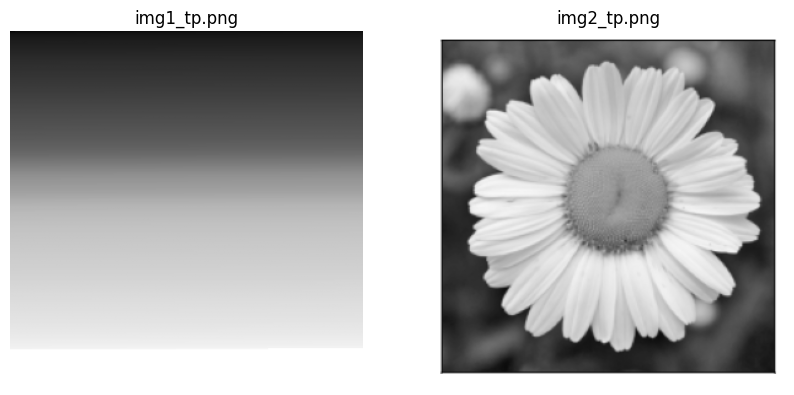

In [7]:
rutas = sorted(glob.glob('/content/img*_tp*.png'))
print('Imágenes encontradas:', [os.path.basename(r) for r in rutas])
if len(rutas) != 2:
    raise FileNotFoundError('Se esperaban 2 imágenes (img1_tp.png e img2_tp.png) en /content/.')

gris = {}
for r in rutas:
    nombre = os.path.basename(r)
    gris[nombre] = cv2.imread(r, cv2.IMREAD_GRAYSCALE)      # lectura en escala de grises
    im = gris[nombre]
    print(f'{nombre}: tamaño={im.shape}, mínimo={im.min()}, máximo={im.max()}, media={im.mean():.1f}')

nombres_gris = list(gris)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, nombre in zip(ax, nombres_gris):
    a.imshow(gris[nombre], cmap='gray', vmin=0, vmax=255)
    a.set_title(nombre)
    a.axis('off')
plt.show()

## 2. Histogramas
Se grafican con dos cantidades de bins para compararlas:
- **256 bins:** un bin por cada nivel de gris (máximo detalle).
- **32 bins:** cada bin agrupa 8 niveles de gris vecinos. Es el que se usa para el análisis, porque con menos bins cada barra junta más píxeles y la forma general de la distribución se ve mucho más clara.

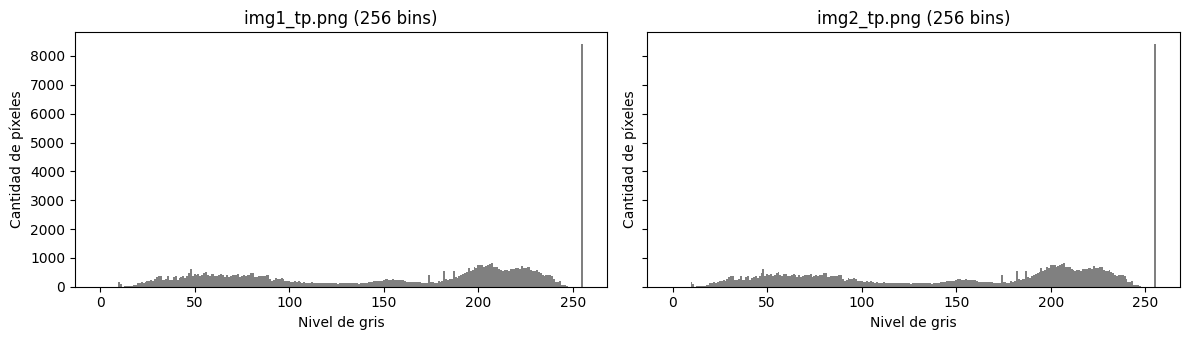

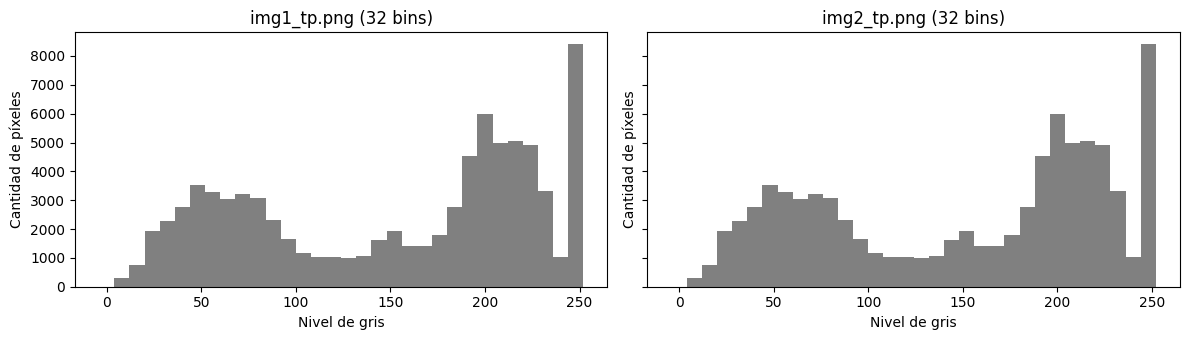

In [8]:
def histograma(img, bins):
    return cv2.calcHist([img], [0], None, [bins], [0, 256]).ravel()

for bins in (256, 32):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
    for a, nombre in zip(ax, nombres_gris):
        h = histograma(gris[nombre], bins)
        a.bar(np.arange(bins) * (256 / bins), h, width=256 / bins, color='gray')
        a.set_title(f'{nombre} ({bins} bins)')
        a.set_xlabel('Nivel de gris')
        a.set_ylabel('Cantidad de píxeles')
    plt.tight_layout()
    plt.show()

## 3. Comparación de los histogramas
Se mide cuánto se parecen los histogramas (correlación: 1 significa idénticos) y cuánto se parecen las imágenes en sí (diferencia media píxel a píxel, en niveles de gris). Después se comprueba si las dos imágenes tienen exactamente los mismos valores de píxel, ordenándolos y comparándolos.

Correlación entre histogramas        : 1.0
¿Histogramas idénticos?              : True
Diferencia media píxel a píxel       : 86.2 niveles de gris
¿Mismos valores de píxel (reordenados)?: True


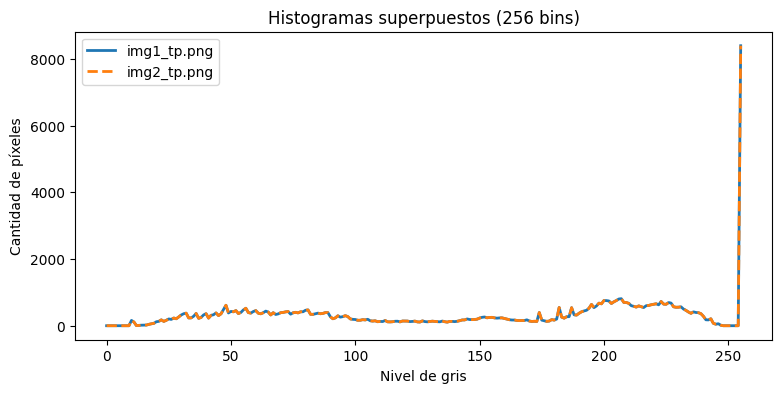

In [9]:
n1, n2 = nombres_gris
h1, h2 = histograma(gris[n1], 256), histograma(gris[n2], 256)

print('Correlación entre histogramas        :', cv2.compareHist(h1.astype(np.float32), h2.astype(np.float32), cv2.HISTCMP_CORREL))
print('¿Histogramas idénticos?              :', np.array_equal(h1, h2))
print('Diferencia media píxel a píxel       :', round(float(np.abs(gris[n1].astype(int) - gris[n2].astype(int)).mean()), 1), 'niveles de gris')
print('¿Mismos valores de píxel (reordenados)?:', np.array_equal(np.sort(gris[n1].ravel()), np.sort(gris[n2].ravel())))

plt.figure(figsize=(9, 4))
plt.plot(h1, label=n1, linewidth=2)
plt.plot(h2, '--', label=n2, linewidth=2)
plt.xlabel('Nivel de gris')
plt.ylabel('Cantidad de píxeles')
plt.title('Histogramas superpuestos (256 bins)')
plt.legend()
plt.show()

## 4. Resultados

### Lo que observo
- Las imágenes son distintas (una margarita y un degradé sin ningún objeto), con una diferencia media de unos 86 niveles de gris por píxel.
- Aun así, **los histogramas son idénticos** (correlación 1,0, curvas superpuestas). La comprobación de valores ordenados lo explica porque las dos imágenes tienen **exactamente los mismos píxeles, solo que en distinto lugar**.
- Con **256 bins** el gráfico es muy detallado pero ruidoso, y sobresale una barra altísima en 255 (blanco puro). Con **32 bins** se observa una "cumulo" de tonos oscuros (alrededor de 50-75), otro cumulo más alto de tonos claros (alrededor de 200-220), un valle en el medio y una barra muy alta en el último bin, con unos 8400 píxeles (cerca del 10 % de la imagen).

### pueden ser de utiidad tomar  como features los histogramas ?
- **Solos, no.** Dicen cuántos píxeles hay de cada tono, pero no dónde están. Las dos imágenes tienen el mismo histograma y son completamente distintas, así que un modelo que solo los mire no podría diferenciarlas. Para detectar objetos sirven todavía menos, porque se pierde la posición.
- **Sí pueden ayudar** cuando las clases se distinguen por su cantidad de claros y oscuros (por ejemplo, fotos de día y de noche), y son rápidos de calcular y de tamaño fijo. Lo más razonable es usarlos como complemento de features con información espacial (bordes, texturas, formas) o usar redes convolucionales.

### Conclusión
El histograma resume qué tonos tiene una imagen, pero no cómo están distribuidos en el espacio. Dos imágenes muy distintas pueden tener el mismo histograma, así que no alcanza como única feature.